## Ecuaciones Diferenciales 0724

Este nootebook tiene como objetivo resolver ecuaciones diferenciales ordinarias, sistemas de ecuaciones diferenciales y ecuaciones diferenciales de orden superior.
Las soluciones son numéricas y serán obtenidas con el *solve_ivp* de la librería scipy.

#### Ecuaciones Diferenciales Ordinarias

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

$$\frac{dy}{dt} = -2y +sen(t)$$

In [4]:
#Función de Ec. Diff
def dydt(t, y):
    return -2*y + np.sin(t)

#Intervalo y condiciones iniciales
tspan = np.array([0,1])
yo = np.array([0])

#Solver
sol = solve_ivp(dydt,tspan,yo,max_step=0.01)

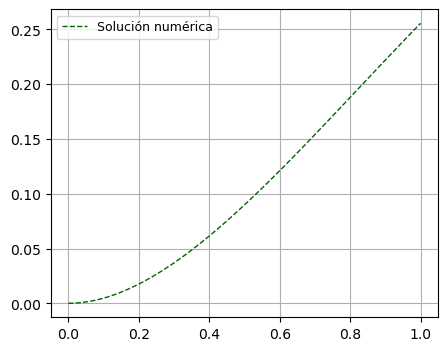

In [9]:
#Gráfico
plt.figure(figsize=(5,4))
plt.plot(sol.t, sol.y[0], '--', color='darkgreen', lw=1, label='Solución numérica')
plt.legend(fontsize=9)
plt.grid(True)
plt.show()

#### Sistemas de Ecuaciones Diferenciales de Primer Orden

Un sistema de ecuaciones diferenciales es un conjunto de varias ecuaciones diferenciales con varias funciones incógnitas y un conjunto de condiciones de contorno. Una solución del mismo es un conjunto de funciones diferenciables que satisfacen todas y cada una de las ecuaciones del sistema (wikipedia, 2024).

$$
\left\{
\begin{array}{ll}
\dfrac{dx}{dt} = -\dfrac{1}{3}x + \dfrac{1}{12}y & \quad x(0) = 20 \\
\dfrac{dy}{dt} = \dfrac{1}{3}x - \dfrac{1}{3}y & \quad y(0) = 12 
\end{array}
\right.$$

El sistema de ecuaciones se cambia a una $\frac{d\vec{S}}{dt}$, donde $\vec{S} = (x,y)$, por lo que la forma vectorial de este arreglo sería

$$\frac{d\vec{S}}{dt} = \begin{bmatrix} x \\ y \end{bmatrix} =
\begin{bmatrix}
-\dfrac{1}{3}x + \dfrac{1}{12}y \\
\dfrac{1}{3}x - \dfrac{1}{3}y
\end{bmatrix}
$$


In [11]:
#Función
def dSdt(t,S):
    x,y = S
    return [-(1/3)*x + (1/12)*y,
           (1/3)*x - (1/3)*y]

#Condiciones iniciales
xo = 20
yo = 12
So = (xo,yo)

#Intervalo de solución
tspan = np.array([0,30])

#Solver
sol = solve_ivp(dSdt, tspan, So, max_step=0.01)

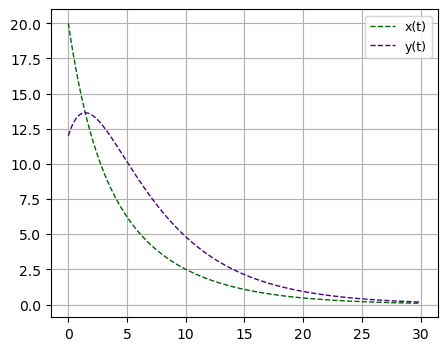

In [14]:
#Gráfico
plt.figure(figsize=(5,4))
plt.plot(sol.t, sol.y[0], '--', color='darkgreen', lw=1, label='x(t)')
plt.plot(sol.t, sol.y[1], '--', color='indigo', lw=1, label='y(t)')
plt.legend(fontsize=9)
plt.grid(True)
plt.show()

#### Ecuaciónes Diferenciales de Orden Superior

$$\frac{d^2x}{dt^2} +\frac{1}{2}\frac{dx}{dt} + x = 0 $$

$$\frac{d^2x}{dt^2} = -\frac{1}{2}\frac{dx}{dt} - x$$

Una Ec. diferencial de orden $n$ se puede "descomponer" en un sistema de $n$ Ec. diferenmciales de primer orden, en este caso, dos. Se comienza con un cambio de variables, definiendolas de la siguiente forma

$$y_{1} = x$$
$$y_{2} = \dot{x}$$

Al diferenciar las variables con respecto de $t$ se puede notar que

$$\dot{y_{1}} = \dot{x} = y_{2}$$
$$\dot{y_{2}} = \ddot{x} = -by_{2} - ky_{1}$$

Para finalmente tener

$$
\left\{
\begin{array}{ll}
\dot{y_{1}} = y_{2} \\
\dot{y_{2}} =  -\frac{1}{2}y_{2} - y_{1}
\end{array}
\right.$$


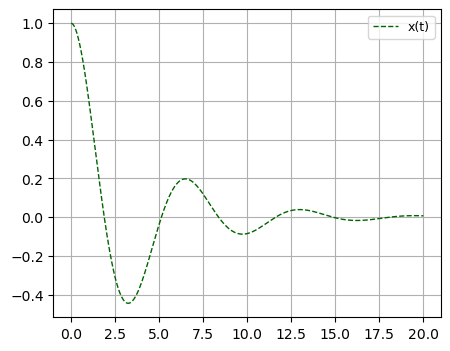

In [17]:
#Función
def dSdt(t,S):
    y1,y2 = S
    return [y2,
           -(1/2)*y2 - y1]

#Condiciones iniciales
y10 = 1
y20 = 0
So = (y10,y20)

#Tiempo de solución
tspan = np.array([0,20])

#Solver
sol = solve_ivp(dSdt, tspan, So, max_step=0.01)

#Gráfica
plt.figure(figsize=(5,4))
plt.plot(sol.t, sol.y[0], '--', color='darkgreen', lw=1, label='x(t)')
#plt.plot(sol.t, sol.y[1], '--', color='indigo', lw=1, label='y(t)')
plt.legend(fontsize=9)
plt.grid(True)
plt.show()